# DSCI 552 - Homework 6
Yash Desai

Submission notebook: required subparts, executable analysis code, saved outputs and plots. `RUN_FULL_ANALYSIS=False` shows the saved model runs while executing preparation/reporting cells; set it to `True` to refit. The full study notebook is preserved separately. Optional Question 6 is excluded. The model-definition qualification for 1(e)-(f) is stated below.

The notebook's own print export includes all cells and outputs. Its verified page count and print settings are recorded in README.md; native GitHub/Jupyter print layouts may differ.

## Setup
Import the tools, locate the data/results folders and set the random seed.

In [1]:
from pathlib import Path
import io, json, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
    accuracy_score, recall_score, precision_score, average_precision_score)

ROOT = Path.cwd()
if not (ROOT/'data').exists() and (ROOT/'hw6'/'data').exists():
    ROOT = ROOT/'hw6'
DATA = ROOT/'data'
OUT = ROOT/'results'
SEED = 552
THREADS = 4
BOOST_THREADS = 1
ALPHAS = [0.0001, 0.001, 0.01, 0.1]
ROUNDS = 100
RUN_FULL_ANALYSIS = False
results = json.loads((OUT/'results.json').read_text())
print('Full model refit enabled:', RUN_FULL_ANALYSIS)

def evaluation_impute(frame):
    """Follow the homework footnote: use this unlabeled evaluation batch's medians."""
    return SimpleImputer(strategy='median', keep_empty_features=True).fit_transform(frame)

Full model refit enabled: False


## 1(a). Load the APS data
The official training/test split is retained: 60,000 training rows, 16,000 test rows, and 170 predictors. `pos=1` means an APS-related failure; `neg=0` means a failure involving another component. The CSVs are included; the loader can download them if missing.

In [2]:
def load_data():
    DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
    names=['aps_failure_training_set.csv','aps_failure_test_set.csv']
    if not all((DATA/n).exists() for n in names):
        url='https://archive.ics.uci.edu/static/public/421/aps+failure+at+scania+trucks.zip'
        print('Downloading the official APS archive...',flush=True)
        try:
            with urllib.request.urlopen(url,timeout=180) as r:
                z=zipfile.ZipFile(io.BytesIO(r.read()))
            for n in names:
                matches=[m for m in z.namelist() if Path(m).name==n]
                if len(matches)!=1: raise ValueError(f'Missing or ambiguous archive member: {n}')
                (DATA/n).write_bytes(z.read(matches[0]))
        except Exception as e:
            raise RuntimeError('Download failed. Download the APS ZIP from UCI manually and put both CSVs in data/.') from e
    frames=[]
    for n in names:
        lines=(DATA/n).read_text().splitlines()
        start=next(i for i,l in enumerate(lines) if l.startswith('class,'))
        frames.append(pd.read_csv(io.StringIO('\n'.join(lines[start:])),na_values='na'))
    tr,te=frames
    assert tr.shape==(60000,171) and te.shape==(16000,171), (tr.shape,te.shape)
    assert tr.columns.equals(te.columns)
    assert set(tr['class'])=={'neg','pos'}
    X=tr.drop(columns='class'); T=te.drop(columns='class')
    y=tr['class'].map({'neg':0,'pos':1}).to_numpy()
    yt=te['class'].map({'neg':0,'pos':1}).to_numpy()
    assert y.sum()==1000 and yt.sum()==375
    return X,T,y,yt

X, T, y, yt = load_data()
print('Training predictors:', X.shape, '| Test predictors:', T.shape)
print('Predictors used by every model:', X.shape[1])

Training predictors: (60000, 170) | Test predictors: (16000, 170)
Predictors used by every model: 170


## 1(b)(i). Missing values
Options include mean/median/mode filling, KNN, iterative or multiple imputation, missingness indicators, and models with native missing-value handling. Dropping incomplete rows could discard substantial data. Median filling is scalable and less sensitive to extremes, but may reduce variation and distort correlations. All rows and predictors are retained; an entirely missing column receives zero.

To follow the homework footnote, training and each unlabeled validation/test batch use separate median imputers. Scalers and models are fitted only on training rows, and SMOTE uses only training-fold rows. Evaluation labels never enter preprocessing. This batch-based imputation differs from the usual deployment practice of reusing stored training medians.

In [3]:
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
A = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
B = evaluation_impute(T)
print('Missing fraction before imputation:', round(X.isna().to_numpy().mean(), 6))
print('Missing cells after imputation:', int(A.isna().sum().sum()))
print('Retained shape:', A.shape)

Missing fraction before imputation: 0.083335
Missing cells after imputation: 0
Retained shape: (60000, 170)


## 1(b)(ii). CV for all 170 features
Calculate `CV = sample SD / mean`, with `ddof=1`, after training-set median filling and before scaling or log transformation. A zero mean gives undefined CV (`NaN`). The code calculates all 170 values; the full CSV is supplied, with the top 13 displayed below.

In [4]:
means = A.mean()
sample_sd = A.std(ddof=1)
cv = sample_sd.div(means.where(means != 0))
cv_table = pd.DataFrame({'mean': means, 'sample_sd': sample_sd,
                         'CV': cv, 'missing_fraction': X.isna().mean()})
if RUN_FULL_ANALYSIS:
    cv_table.to_csv(OUT/'feature_CV_all_170.csv')
print('CV calculated for', len(cv_table), 'features.')
display(cv_table.nlargest(13, 'CV').round(5))

CV calculated for 170 features.


,mean,sample_sd,CV,missing_fraction
cf_000,143107.53413,3.504525e+07,244.88752,0.24768
co_000,143330.01773,3.504525e+07,244.50739,0.24768
ad_000,143438.29207,3.504525e+07,244.32282,0.24768
cs_009,770.50970,1.833278e+05,237.93055,0.01115
dh_000,4392.64083,5.412441e+05,123.21610,0.06680
dj_000,37.27133,4.379166e+03,117.49423,0.06678
ag_000,219.15773,2.036364e+04,92.91776,0.01118
as_000,125.40790,1.095219e+04,87.33250,0.01048
ay_009,1149.61963,9.741156e+04,84.73373,0.01118
ak_000,907.66070,7.299859e+04,80.42498,0.07333


## 1(b)(iii). Correlation matrix
Pearson correlations use all 170 median-imputed training predictors. Strong blocks suggest overlapping information; correlations involving constant columns remain undefined.

Correlation matrix shape: (170, 170)


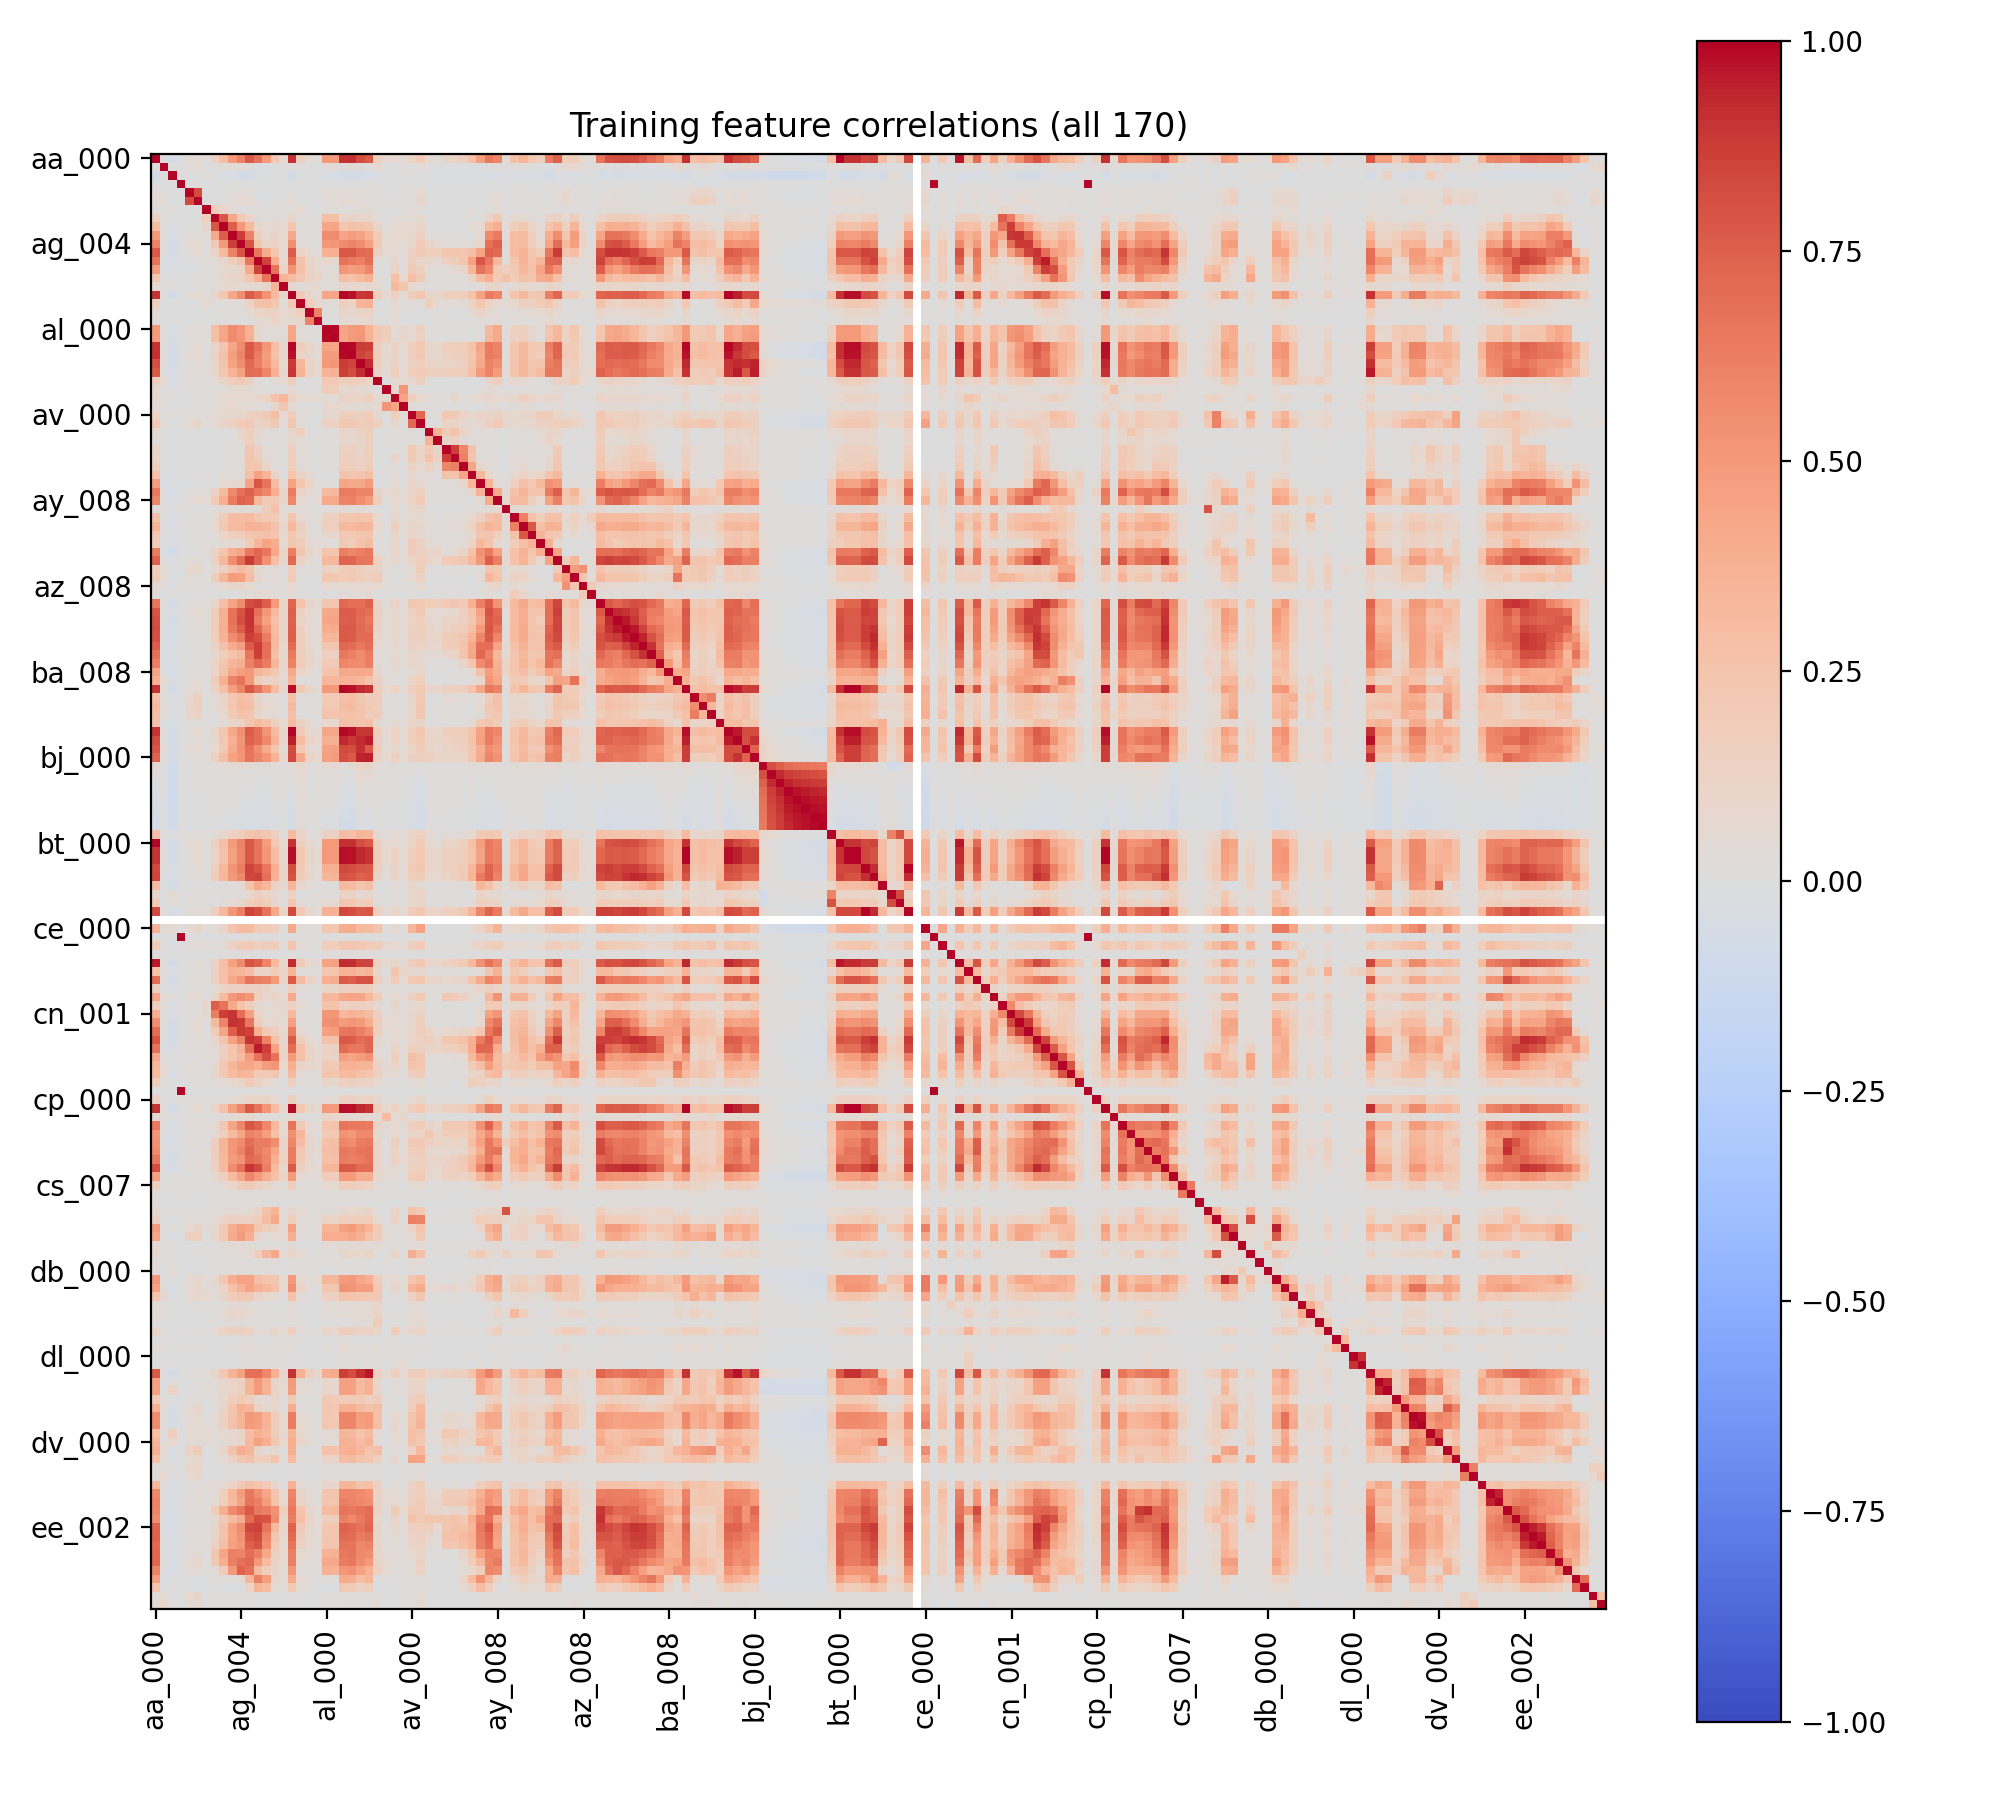

In [5]:
if RUN_FULL_ANALYSIS:
    correlations = A.corr()
    correlations.to_csv(OUT/'correlations_all_170.csv')
    fig, ax = plt.subplots(figsize=(10, 9))
    im = ax.imshow(correlations, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set(xticks=np.arange(0,170,10), yticks=np.arange(0,170,10),
           xticklabels=X.columns[::10], yticklabels=X.columns[::10],
           title='Training feature correlations (all 170)')
    plt.setp(ax.get_xticklabels(), rotation=90)
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(OUT/'correlation.png', dpi=200)
    plt.close(fig)
else:
    correlations = pd.read_csv(OUT/'correlations_all_170.csv', index_col=0)
print('Correlation matrix shape:', correlations.shape)
display(Image(filename=str(OUT/'correlation.png'), width=500))

## 1(b)(iv). Scatter plots, box plots and interpretation
Select `floor(sqrt(170)) = 13` highest finite CV features only for visualization. All 170 features remain in every model. Scatter plots use every training observation; `log1p` makes skewed values visible, and box plots include outliers.

High CV reflects relative dispersion, not necessarily predictive value. Several selected features have similar or zero class medians. Plots suggest associations but cannot establish statistical significance, conditional usefulness or causality.

Selected 13 features: cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000


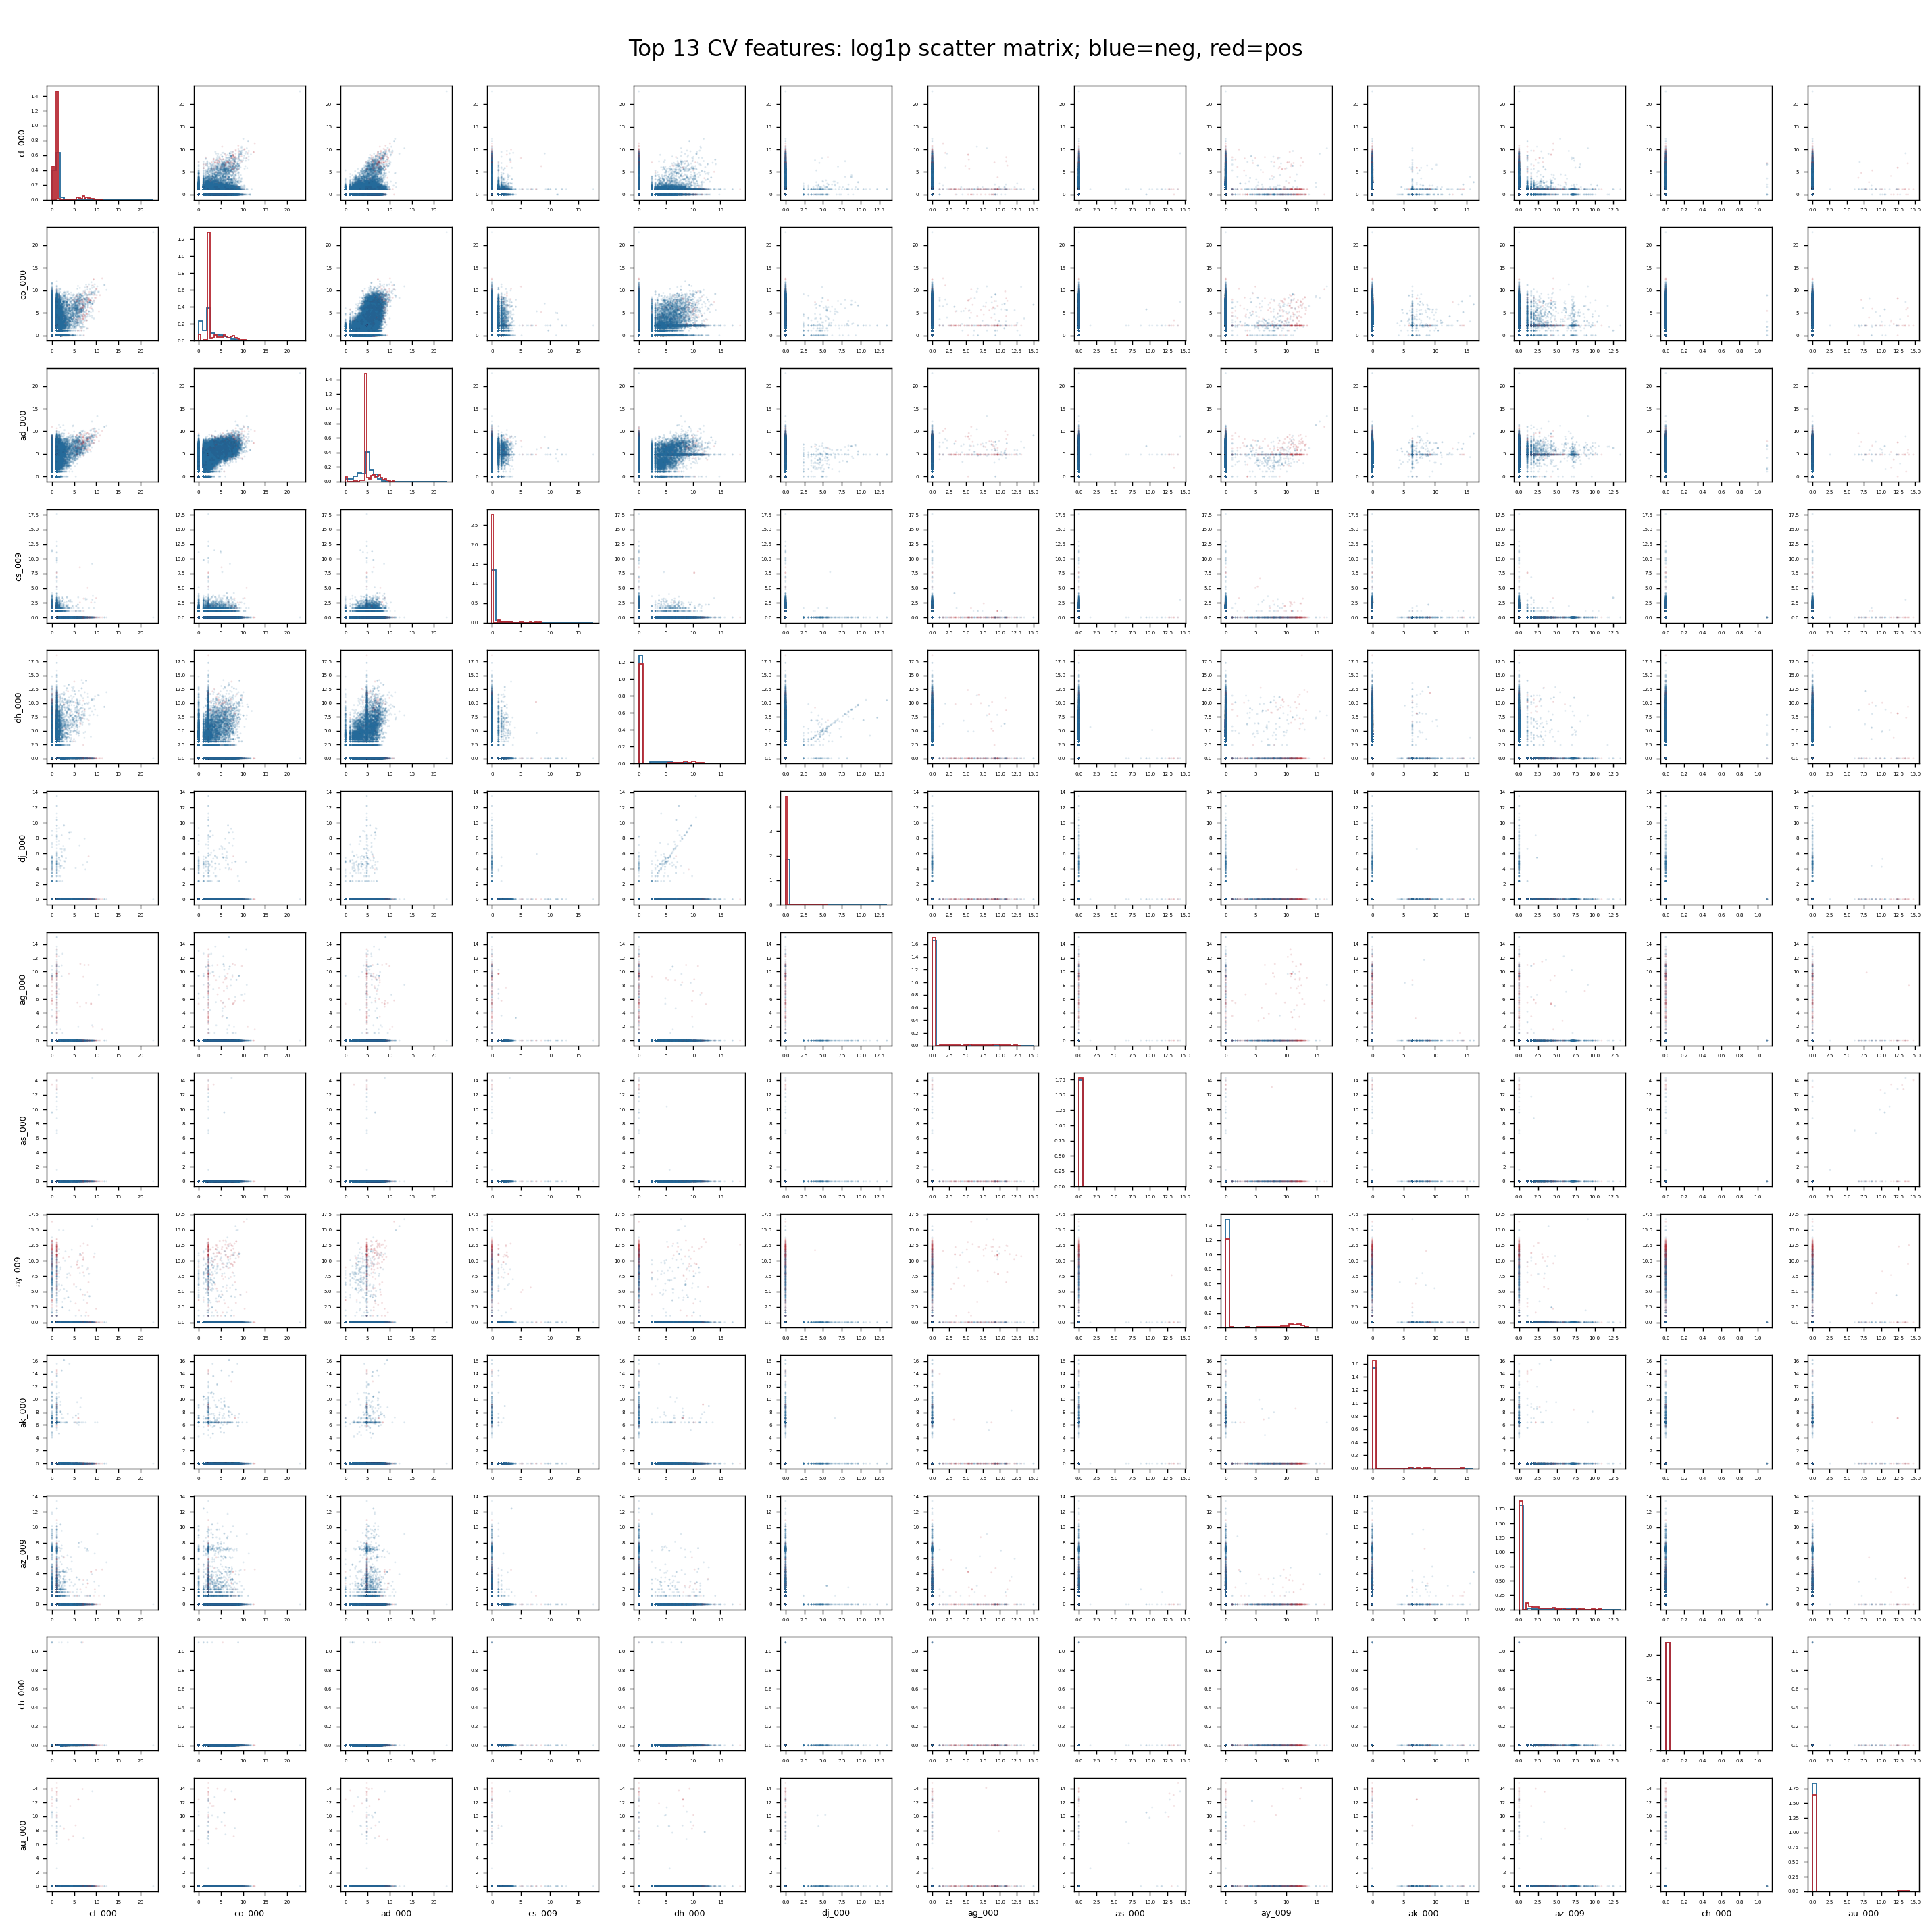

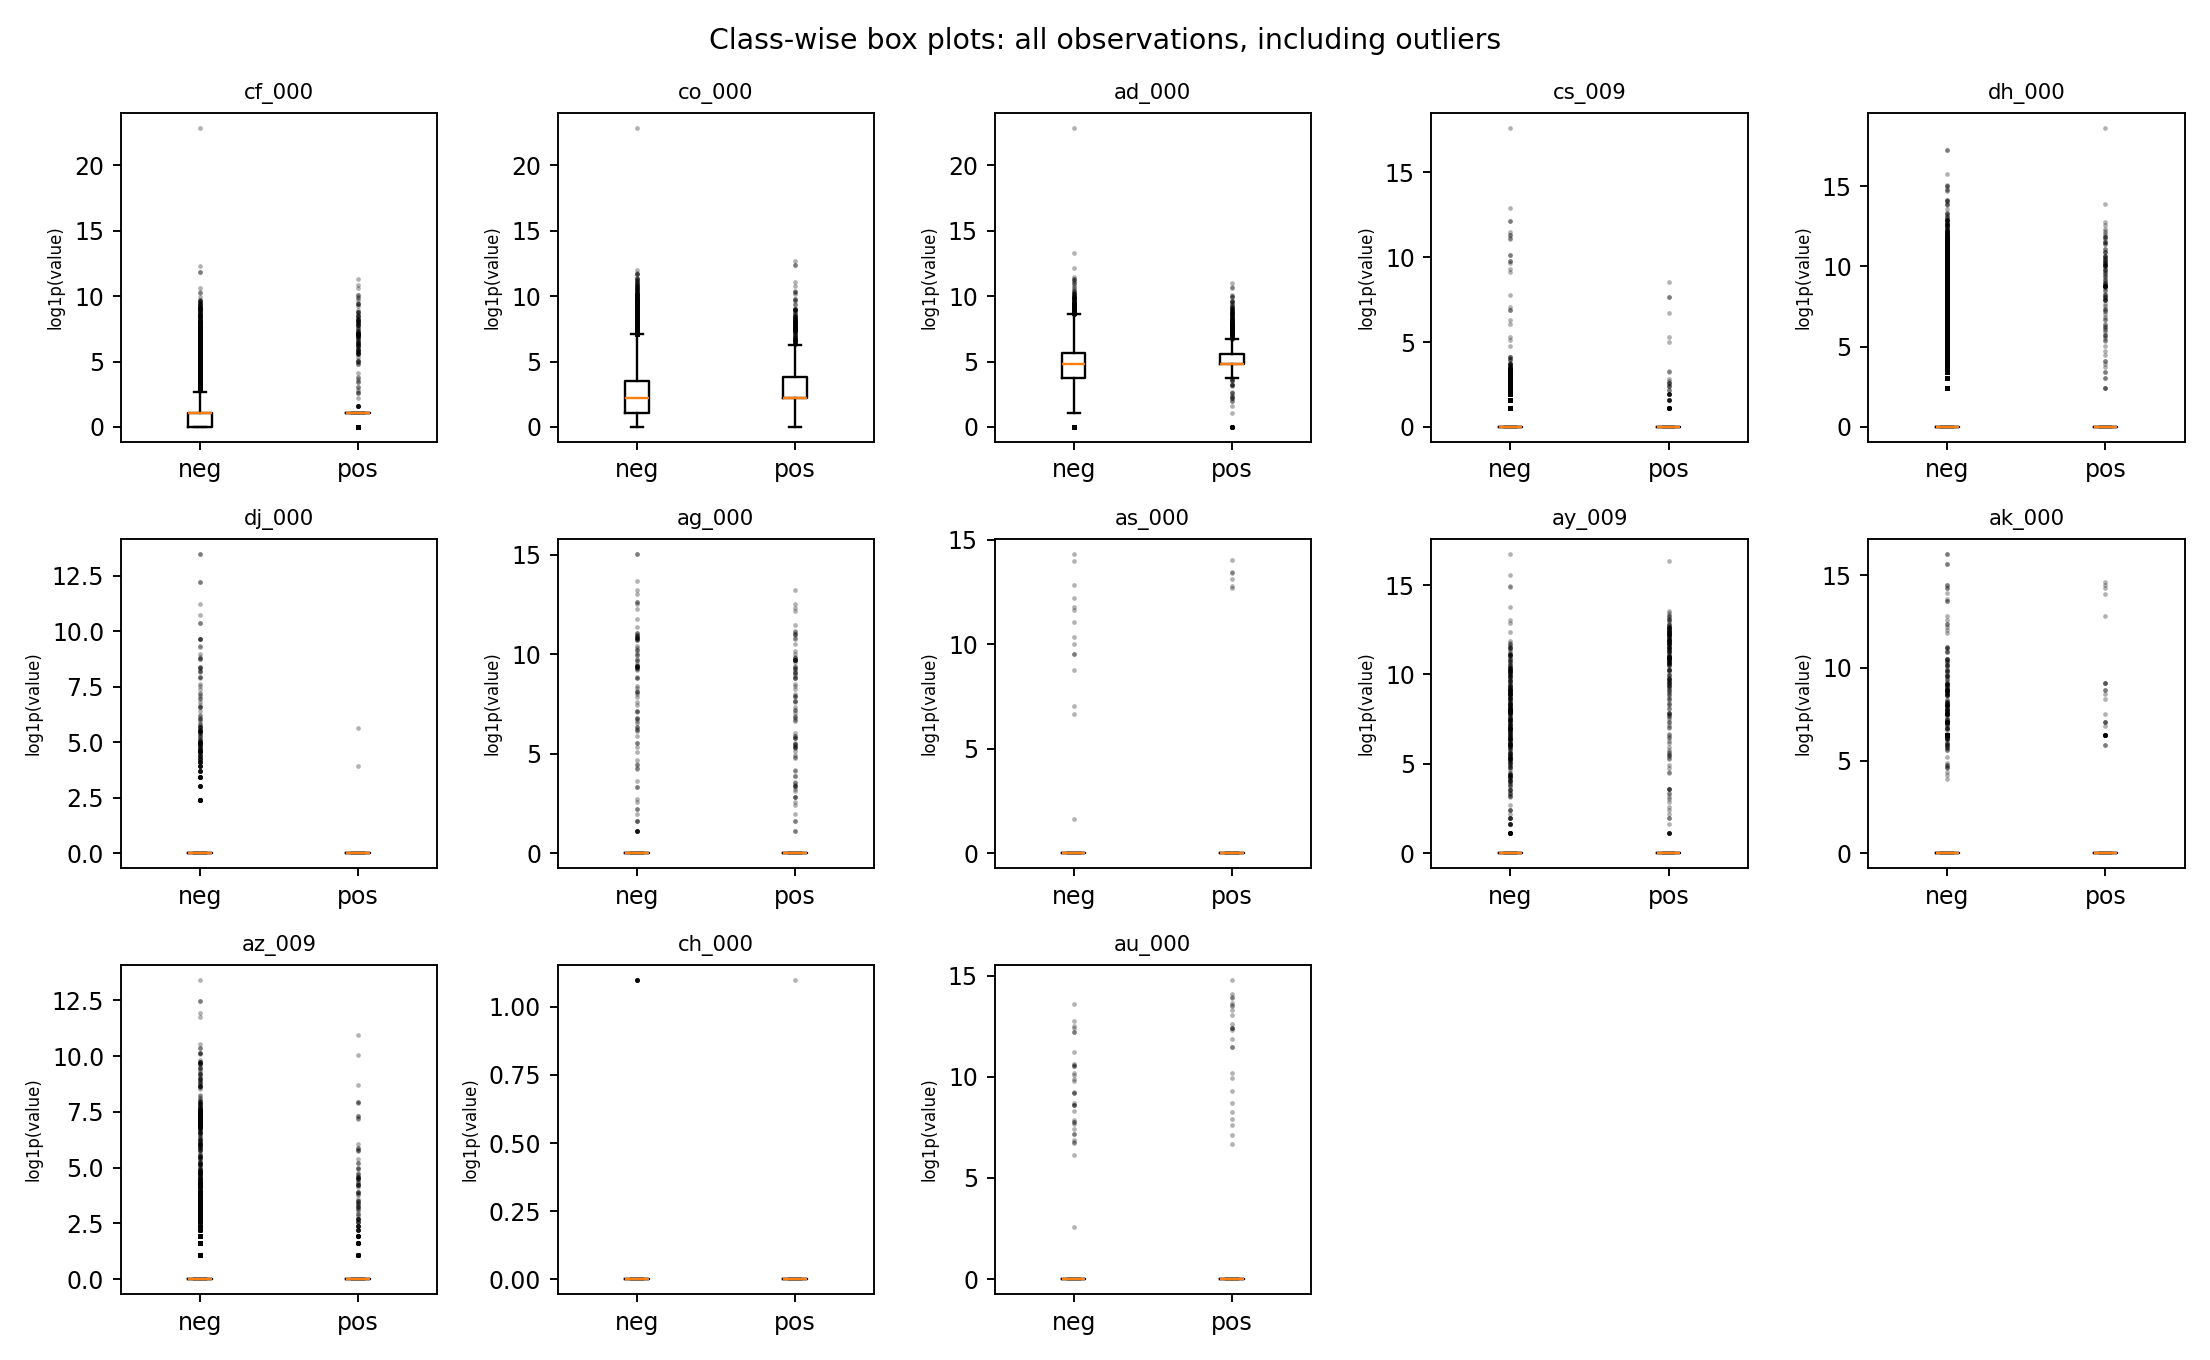

In [6]:
top = cv.replace([np.inf, -np.inf], np.nan).dropna().nlargest(int(np.sqrt(170))).index.tolist()
print('Selected', len(top), 'features:', ', '.join(top))
if RUN_FULL_ANALYSIS:
    # Plot every training observation in the 13-by-13 matrix. The log1p transform
    # makes the skewed values easier to see; CV is still calculated in original units.
    Z=np.log1p(A[top]); n=len(top)
    fig,axes=plt.subplots(n,n,figsize=(22,22))
    colors=np.where(y==1,'#b62832','#246a9a')
    for i in range(n):
      for j in range(n):
        ax=axes[i,j]
        if i==j:
          for c,color in [(0,'#246a9a'),(1,'#b62832')]:
            ax.hist(Z.iloc[y==c,i],bins=25,density=True,histtype='step',color=color)
        else: ax.scatter(Z.iloc[:,j],Z.iloc[:,i],c=colors,s=.4,alpha=.12,rasterized=True)
        ax.tick_params(labelsize=4)
        if i==n-1: ax.set_xlabel(top[j],fontsize=7)
        if j==0: ax.set_ylabel(top[i],fontsize=7)
    fig.suptitle('Top 13 CV features: log1p scatter matrix; blue=neg, red=pos',fontsize=18)
    fig.tight_layout(rect=[0,0,1,.98]); fig.savefig(OUT/'scatter_matrix.png',dpi=130); plt.close(fig)
    fig,axes=plt.subplots(3,5,figsize=(13,8))
    for ax,col in zip(axes.flat,top):
        ax.boxplot([Z.loc[y==0,col],Z.loc[y==1,col]],tick_labels=['neg','pos'],showfliers=True,flierprops={'marker':'.','markersize':2,'alpha':.3})
        ax.set_title(col,fontsize=9); ax.set_ylabel('log1p(value)',fontsize=7)
    for ax in list(axes.flat)[13:]: ax.axis('off')
    fig.suptitle('Class-wise box plots: all observations, including outliers')
    fig.tight_layout(); fig.savefig(OUT/'boxplots.png',dpi=170); plt.close(fig)

display(Image(filename=str(OUT/'scatter_matrix.png'), width=500))
display(Image(filename=str(OUT/'boxplots.png'), width=500))

## 1(b)(v). Class imbalance
Training counts are 59,000 negative and 1,000 positive (59:1). Test counts are 15,625 negative and 375 positive. Always predicting negative gives only 2.34375% test error while missing every APS failure. Overall error must therefore be read alongside recall and false-negative counts.

In [7]:
counts = pd.DataFrame({
    'split':['train','test'],
    'negative':[int((y==0).sum()), int((yt==0).sum())],
    'positive':[int(y.sum()), int(yt.sum())]})
counts['positive_fraction'] = counts['positive']/(counts['negative']+counts['positive'])
display(counts)

,split,negative,positive,positive_fraction
0,train,59000,1000,0.016667
1,test,15625,375,0.023438


## Evaluation used in 1(c)-(f)
Threshold probabilities at 0.5. Confusion-matrix rows are actual `[neg,pos]`, columns predicted `[neg,pos]`. False negatives are missed APS failures; false positives are false alarms. Error is `(FP+FN)/n`; ROC/AUC use probabilities. SMOTE training scores use the original 60,000 rows.

In [8]:
def metrics(y,p):
    if not np.isfinite(p).all() or np.any((p<0)|(p>1)):
        raise ValueError('Predicted probabilities must be finite and in [0,1].')
    pred=(p>=.5).astype(int)
    return dict(error=float(1-accuracy_score(y,pred)),auc=float(roc_auc_score(y,p)),
      recall=float(recall_score(y,pred)),precision=float(precision_score(y,pred,zero_division=0)),
      ap=float(average_precision_score(y,p)),cm=confusion_matrix(y,pred,labels=[0,1]).tolist())

def plot_probabilities(name,y,yt,ps):
    fig,ax=plt.subplots(1,3,figsize=(9,3.1))
    for side,truth,p,a in zip(['train','test'],[y,yt],ps,ax[:2]):
        cm=confusion_matrix(truth,p>=.5,labels=[0,1]); a.imshow(cm,cmap='Blues')
        for (i,j),v in np.ndenumerate(cm): a.text(j,i,str(v),ha='center',va='center',fontsize=11,color='white' if v>cm.max()/2 else 'black')
        a.set(xticks=[0,1],yticks=[0,1],xticklabels=['neg','pos'],yticklabels=['neg','pos'],
          xlabel='Predicted',ylabel='Actual',title=side+' confusion matrix')
    for s,truth,p in zip(['train','test'],[y,yt],ps):
        fpr,tpr,_=roc_curve(truth,p); ax[2].plot(fpr,tpr,label=f'{s}: AUC={roc_auc_score(truth,p):.4f}')
    ax[2].plot([0,1],[0,1],'k--',lw=.7); ax[2].set(xlabel='False positive rate',ylabel='True positive rate',title=name)
    ax[2].legend(fontsize=9); fig.tight_layout(); fig.savefig(OUT/(name+'.png'),dpi=170); plt.close(fig)

def evaluate(name, model, X,T,y,yt, results):
    ps=[model.predict_proba(a)[:,1] for a in (X,T)]
    results[name]={s:metrics(b,p) for s,b,p in zip(['train','test'],[y,yt],ps)}
    np.savez_compressed(OUT/(name+'_predictions.npz'),train=ps[0],test=ps[1])
    plot_probabilities(name,y,yt,ps)
    print(name,results[name],flush=True)

def show_model(name):
    m = results['models'][name]
    display(pd.DataFrame({s:{k:v for k,v in m[s].items() if k!='cm'}
                          for s in ['train','test']}).T.round(6))
    for split in ['train','test']:
        print(split, 'confusion matrix:', m[split]['cm'])
    display(Image(filename=str(OUT/(name+'.png')), width=500))
    return m

## 1(c). Uncompensated random forest
Use 300 bootstrap trees, `max_features='sqrt'`, unrestricted depth, seed 552, and no class compensation. Training/test confusion matrices, ROC, AUC and errors follow.

OOB predictions use trees whose bootstrap samples excluded each observation. OOB error is compared with test error below. The imputer was fitted on the full training set first, so this is the forest's OOB diagnostic rather than a fully cross-fitted preprocessing estimate.

train confusion matrix: [[59000, 0], [0, 1000]]
test confusion matrix: [[15608, 17], [105, 270]]
OOB error: 0.00575
Test minus OOB error: 0.001875


,error,auc,recall,precision,ap
train,0.000000,1.000000,1.00,1.000000,1.000000
test,0.007625,0.994446,0.72,0.940767,0.925627


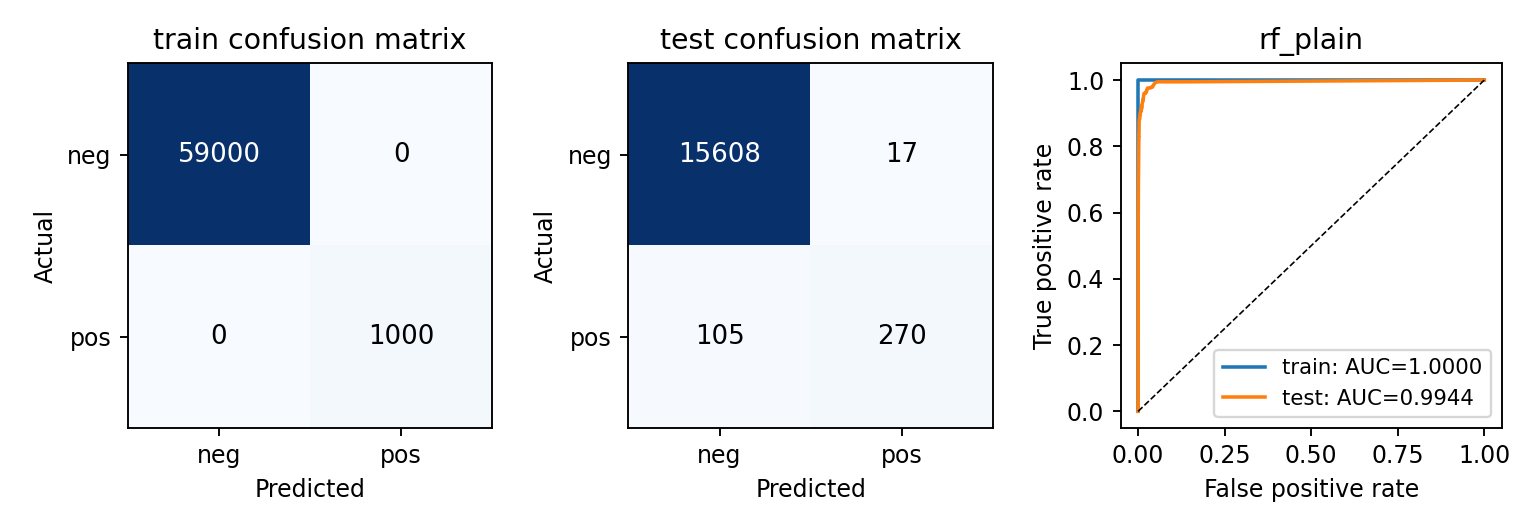

In [9]:
if RUN_FULL_ANALYSIS:
    rf_plain = RandomForestClassifier(n_estimators=300, max_features='sqrt',
        bootstrap=True, oob_score=True, class_weight=None,
        n_jobs=THREADS, random_state=SEED)
    rf_plain.fit(A.to_numpy(dtype='float32'), y)
    evaluate('rf_plain', rf_plain, A.to_numpy(dtype='float32'), B.astype('float32'),
             y, yt, results['models'])
    results['models']['rf_plain']['oob_error'] = float(1-rf_plain.oob_score_)
m = show_model('rf_plain')
print('OOB error:', round(m['oob_error'],6))
print('Test minus OOB error:', round(m['test']['error']-m['oob_error'],6))

## 1(d). Weighted random forest
Imbalance remedies include class weights, balanced bootstraps, over/undersampling, and thresholds selected on training validation data. `balanced_subsample` recalculates inverse-frequency weights per bootstrap; other forest settings match 1(c). Full-training weights would be approximately 0.5085 for neg and 30 for pos.

Here test recall falls from 72.0% to 58.13% and error rises from 0.7625% to 1.06875%. False alarms fall from 17 to 14, but missed failures rise from 105 to 157. Weighting does not improve every metric.

train confusion matrix: [[59000, 0], [0, 1000]]
test confusion matrix: [[15611, 14], [157, 218]]
OOB error: 0.007667
Test minus OOB error: 0.003021


,error,auc,recall,precision,ap
train,0.000000,1.000000,1.000000,1.000000,1.000000
test,0.010687,0.993082,0.581333,0.939655,0.885106


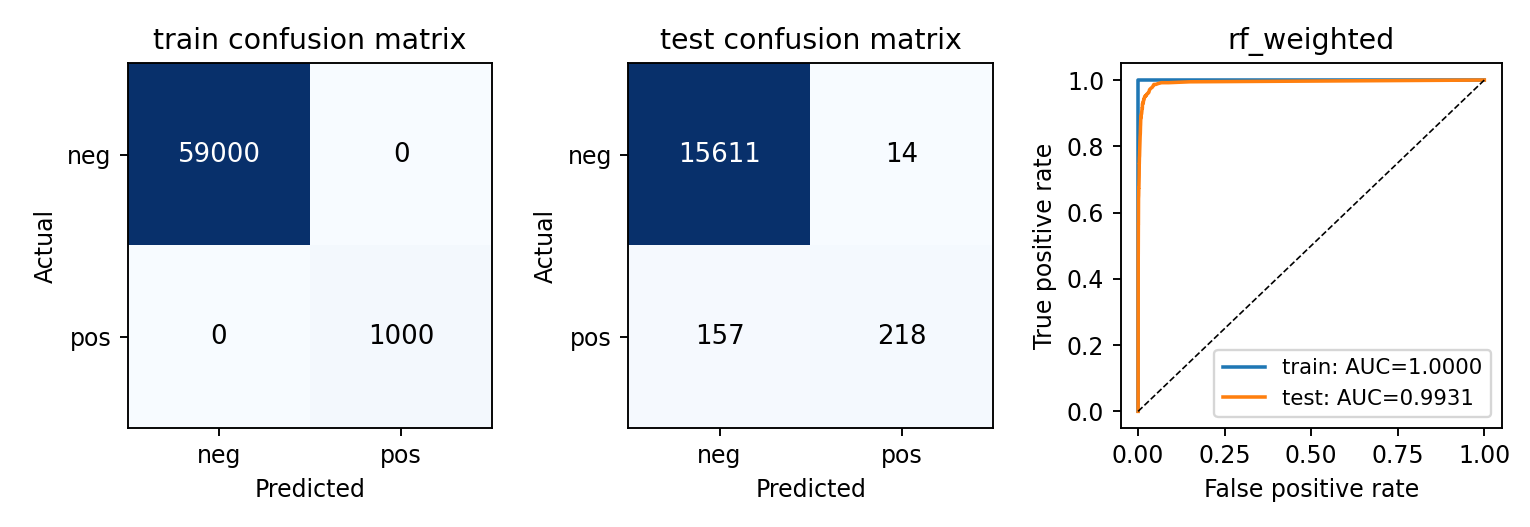

,error,auc,recall,precision,ap,cm
rf_plain,0.007625,0.994446,0.72,0.940767,0.925627,"[[15608, 17], [105, 270]]"
rf_weighted,0.010687,0.993082,0.581333,0.939655,0.885106,"[[15611, 14], [157, 218]]"


In [10]:
if RUN_FULL_ANALYSIS:
    rf_weighted = RandomForestClassifier(n_estimators=300, max_features='sqrt',
        bootstrap=True, oob_score=True, class_weight='balanced_subsample',
        n_jobs=THREADS, random_state=SEED)
    rf_weighted.fit(A.to_numpy(dtype='float32'), y)
    evaluate('rf_weighted', rf_weighted, A.to_numpy(dtype='float32'), B.astype('float32'),
             y, yt, results['models'])
    results['models']['rf_weighted']['oob_error'] = float(1-rf_weighted.oob_score_)
m = show_model('rf_weighted')
print('OOB error:', round(m['oob_error'],6))
print('Test minus OOB error:', round(m['test']['error']-m['oob_error'],6))
display(pd.DataFrame({k:results['models'][k]['test'] for k in ['rf_plain','rf_weighted']}).T)

## 1(e). L1-logistic XGBoost and cross-validation
**Model-definition qualification:** `gblinear` with `binary:logistic` fits one global logistic model. Standard XGBoost does not fit logistic regressions at tree nodes; tree-booster `reg_alpha` penalizes leaf scores. The literal node-wise model-tree wording therefore remains unresolved.

For the implemented global model, use median filling, `log1p`, then StandardScaler. Training-only checks found saturation without the log transform. Fit 100 rounds at learning rate 0.1 with deterministic cyclic coordinate descent and no L2 penalty. Five shuffled, stratified folds (seed 552) choose among positive alphas `{0.0001,0.001,0.01,0.1}` by mean classification error, with AUC as tie breaker. Alpha 0.0001 is selected.

Each training fold fits its imputer/scaler; validation uses its own unlabeled batch medians and the training scaler, matching the footnote. Selected-alpha CV error may be optimistic because the same CV chooses alpha; it is not nested CV. The independent test comparison appears below.

In [11]:
def booster(alpha):
    if alpha <= 0:
        raise ValueError("Use a positive alpha for the L1-penalized models.")
    from xgboost import XGBClassifier
    return XGBClassifier(booster='gblinear',objective='binary:logistic',
       reg_alpha=alpha,reg_lambda=0,n_estimators=ROUNDS,learning_rate=.1,
       updater='coord_descent',feature_selector='cyclic',n_jobs=BOOST_THREADS,
       random_state=SEED,eval_metric='logloss')

def cv_linear(X,y,smote):
    from imblearn.over_sampling import SMOTE
    # Fit the model and scaler on training rows. Impute validation using its own unlabeled batch, as the footnote asks.
    folds=list(StratifiedKFold(5,shuffle=True,random_state=SEED).split(X,y))
    errors=np.zeros((len(ALPHAS),5)); aucs=np.zeros_like(errors)
    oof=np.zeros((len(ALPHAS),len(y)),dtype=np.float32)
    for k,(a,b) in enumerate(folds):
        imp=SimpleImputer(strategy='median',keep_empty_features=True)
        scaler=StandardScaler()
        xa=scaler.fit_transform(np.log1p(imp.fit_transform(X.iloc[a]))).astype('float32')
        xb=scaler.transform(np.log1p(evaluation_impute(X.iloc[b]))).astype('float32')
        ya=y[a]
        if smote: xa,ya=SMOTE(random_state=SEED+k,k_neighbors=5).fit_resample(xa,ya)
        for j,alpha in enumerate(ALPHAS):
            model=booster(alpha).fit(xa,ya)
            p=model.predict_proba(xb)[:,1]; oof[j,b]=p
            print(f'SMOTE={smote}, fold={k+1}, alpha={alpha}: fitted',flush=True)
            errors[j,k]=np.mean((p>=.5)!=y[b]); aucs[j,k]=roc_auc_score(y[b],p)
        print(f'SMOTE={smote}: finished fold {k+1}/5',flush=True)
    table=pd.DataFrame({'alpha':ALPHAS,'mean_error':errors.mean(1),
       'sd_error':errors.std(1,ddof=1),'mean_auc':aucs.mean(1)})
    # Choose the lowest CV error. If errors tie, prefer the higher AUC.
    best=int(table.sort_values(['mean_error','mean_auc'],ascending=[True,False]).index[0])
    tag='smote' if smote else 'plain'
    table.to_csv(OUT/f'cv_{tag}.csv',index=False)
    np.savez_compressed(OUT/f'oof_{tag}.npz',probability=oof[best],truth=y)
    return ALPHAS[best], float(errors[best].mean())

train confusion matrix: [[58896, 104], [409, 591]]
test confusion matrix: [[15593, 32], [158, 217]]
Selected alpha: 0.0001 | CV error: 0.009083
Test error: 0.011875 | Test minus CV error: 0.002792


,alpha,mean_error,sd_error,mean_auc
0,0.0001,0.009083,0.000738,0.985116
1,0.0010,0.009883,0.001181,0.983324
2,0.0100,0.012783,0.001018,0.965824
3,0.1000,0.016667,0.000000,0.500000


,error,auc,recall,precision,ap
train,0.008550,0.986349,0.591000,0.850360,0.797455
test,0.011875,0.991615,0.578667,0.871486,0.839178


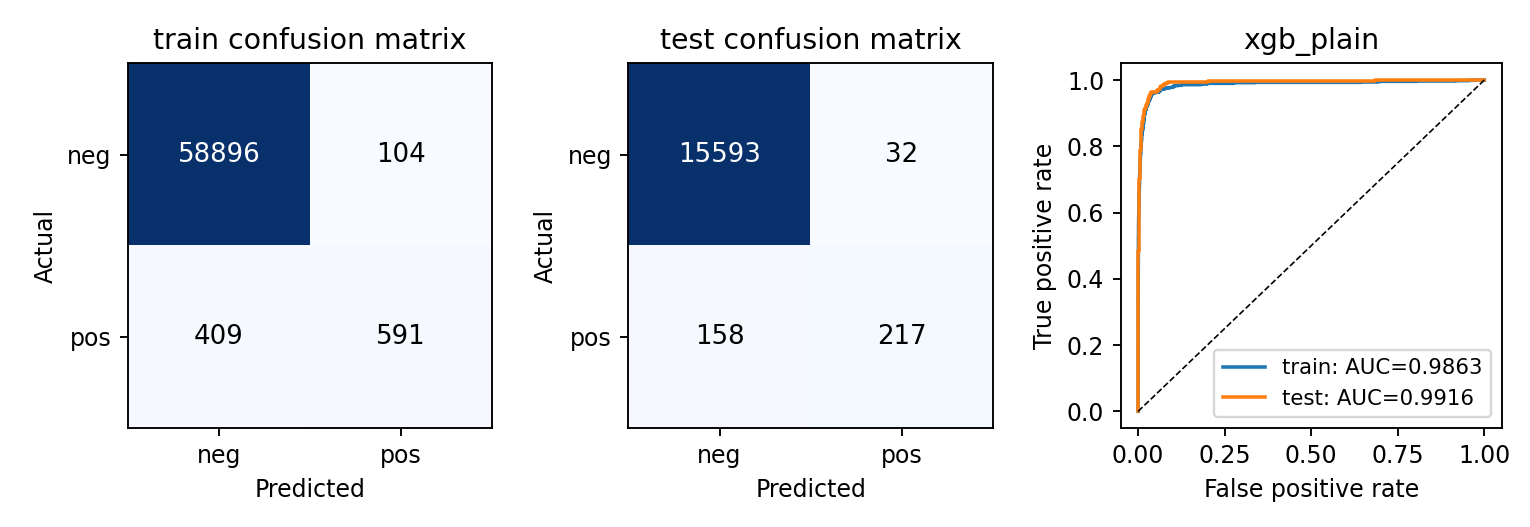

In [12]:
if RUN_FULL_ANALYSIS:
    alpha, cv_error = cv_linear(X, y, smote=False)
    imp_linear = SimpleImputer(strategy='median', keep_empty_features=True)
    scaler = StandardScaler()
    xa = scaler.fit_transform(np.log1p(imp_linear.fit_transform(X))).astype('float32')
    xb = scaler.transform(np.log1p(evaluation_impute(T))).astype('float32')
    xgb_plain = booster(alpha).fit(xa, y)
    evaluate('xgb_plain', xgb_plain, xa, xb, y, yt, results['models'])
    results['models']['xgb_plain'].update(alpha=alpha, cv_error=cv_error, fit_rows=len(y))
display(pd.read_csv(OUT/'cv_plain.csv').round(6))
m = show_model('xgb_plain')
print('Selected alpha:',m['alpha'],'| CV error:',round(m['cv_error'],6))
print('Test error:',round(m['test']['error'],6),
      '| Test minus CV error:',round(m['test']['error']-m['cv_error'],6))

## 1(f). SMOTE and comparison
SMOTE(k=5) interpolates between neighboring minority observations. Apply it only to the transformed training part of each fold. Validation uses its own unlabeled medians and the training scaler; it is never resampled. SMOTE before splitting folds would leak validation information into synthetic training examples. The folds and positive-alpha grid match 1(e); alpha 0.0001 is selected.

The final fit uses all training data and SMOTE produces 118,000 rows, 59,000 per class. Scores use the original training/test rows. The same global-linear versus node-wise-model qualification applies.

Test recall rises from 57.87% to 95.73%, and missed failures fall from 158 to 16. False alarms rise from 32 to 645; error rises from 1.1875% to 4.13125%. AUC changes from 0.99161 to 0.99047. The preferred tradeoff depends on the relative costs of missed failures and false alarms.

train confusion matrix: [[56516, 2484], [43, 957]]
test confusion matrix: [[14980, 645], [16, 359]]
Selected alpha: 0.0001 | CV error: 0.0421
Final SMOTE fitting rows: 118000
Test minus CV error: -0.000788


,alpha,mean_error,sd_error,mean_auc
0,0.0001,0.042100,0.001807,0.984367
1,0.0010,0.044050,0.001806,0.984628
2,0.0100,0.050117,0.001178,0.981787
3,0.1000,0.064133,0.003117,0.968300


,error,auc,recall,precision,ap
train,0.042117,0.987560,0.957000,0.278117,0.767813
test,0.041312,0.990472,0.957333,0.357570,0.824528


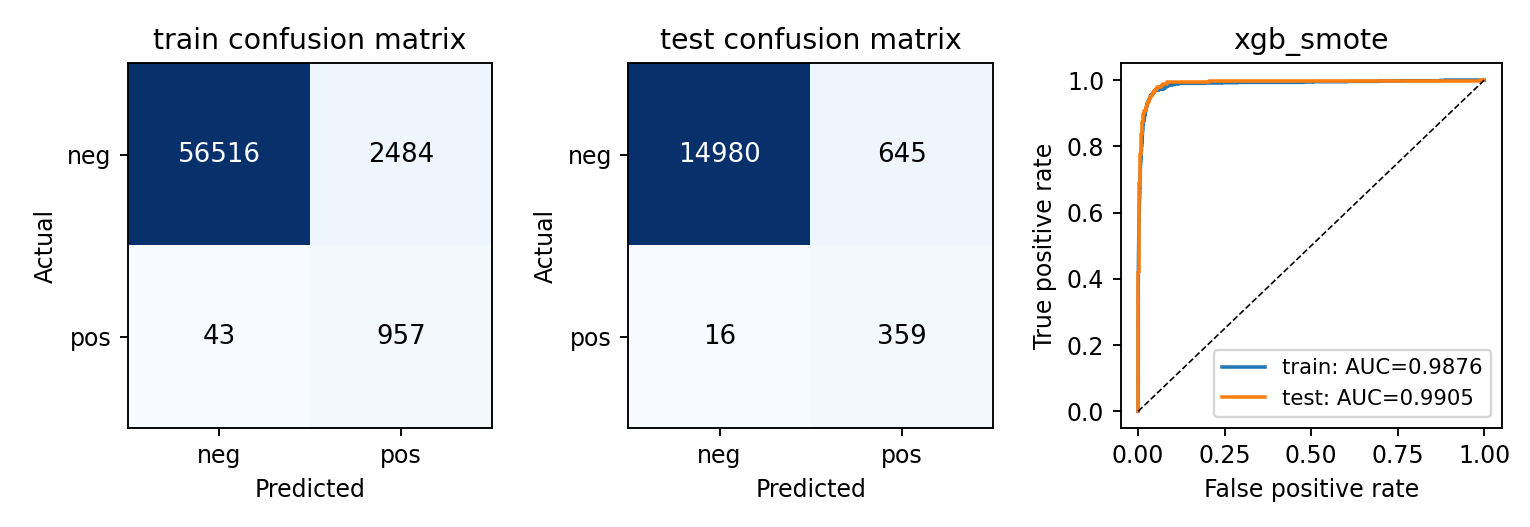

,error,auc,recall,precision,ap,cm
xgb_plain,0.011875,0.991615,0.578667,0.871486,0.839178,"[[15593, 32], [158, 217]]"
xgb_smote,0.041312,0.990472,0.957333,0.35757,0.824528,"[[14980, 645], [16, 359]]"


In [13]:
if RUN_FULL_ANALYSIS:
    from imblearn.over_sampling import SMOTE
    alpha, cv_error = cv_linear(X, y, smote=True)
    imp_smote = SimpleImputer(strategy='median', keep_empty_features=True)
    scaler_smote = StandardScaler()
    xa = scaler_smote.fit_transform(np.log1p(imp_smote.fit_transform(X))).astype('float32')
    xb = scaler_smote.transform(np.log1p(evaluation_impute(T))).astype('float32')
    fitx, fity = SMOTE(random_state=SEED, k_neighbors=5).fit_resample(xa, y)
    xgb_smote = booster(alpha).fit(fitx, fity)
    evaluate('xgb_smote', xgb_smote, xa, xb, y, yt, results['models'])
    results['models']['xgb_smote'].update(alpha=alpha, cv_error=cv_error, fit_rows=len(fity))
display(pd.read_csv(OUT/'cv_smote.csv').round(6))
m = show_model('xgb_smote')
print('Selected alpha:',m['alpha'],'| CV error:',round(m['cv_error'],6))
print('Final SMOTE fitting rows:', m['fit_rows'])
print('Test minus CV error:',round(m['test']['error']-m['cv_error'],6))
display(pd.DataFrame({k:results['models'][k]['test'] for k in ['xgb_plain','xgb_smote']}).T)
if RUN_FULL_ANALYSIS:
    (OUT/'results.json').write_text(json.dumps(results, indent=2))

## 2. ISLR 6.6.3 - relaxing the lasso constraint

The useful idea here is that s controls how much freedom the lasso has. We minimize RSS while requiring sum_j |beta_j| <= s. At s=0, every slope is zero. As s gets larger, more coefficient values become possible. Once the least-squares solution fits inside the constraint, loosening it further makes no difference.

### 2(a)

Training RSS decreases or stays the same, so choice iv is the best answer. A larger s keeps all the earlier solutions available and adds new ones. The best fit therefore cannot become worse on the same training data.

### 2(b)

Test RSS usually falls at first and then rises, which is choice ii. Initially, less shrinkage helps the model capture real patterns. With too much freedom, it can also fit noise. This is the usual bias-variance pattern, rather than a rule that every individual data set must follow.

### 2(c)

Variance generally increases, so choose iii. A more flexible fit can change more when we replace the training sample.

### 2(d)

Squared bias generally decreases, so choose iv. Relaxing the constraint reduces the restriction that was pulling the coefficients toward zero.

### 2(e)

Irreducible error stays constant, so choose v. Changing s changes the model, but it does not remove the underlying noise in the response.

### Illustration for 2(a)-(e)
Schematic trends, not APS measurements: decreasing bias and increasing variance explain the usual test-error curve.

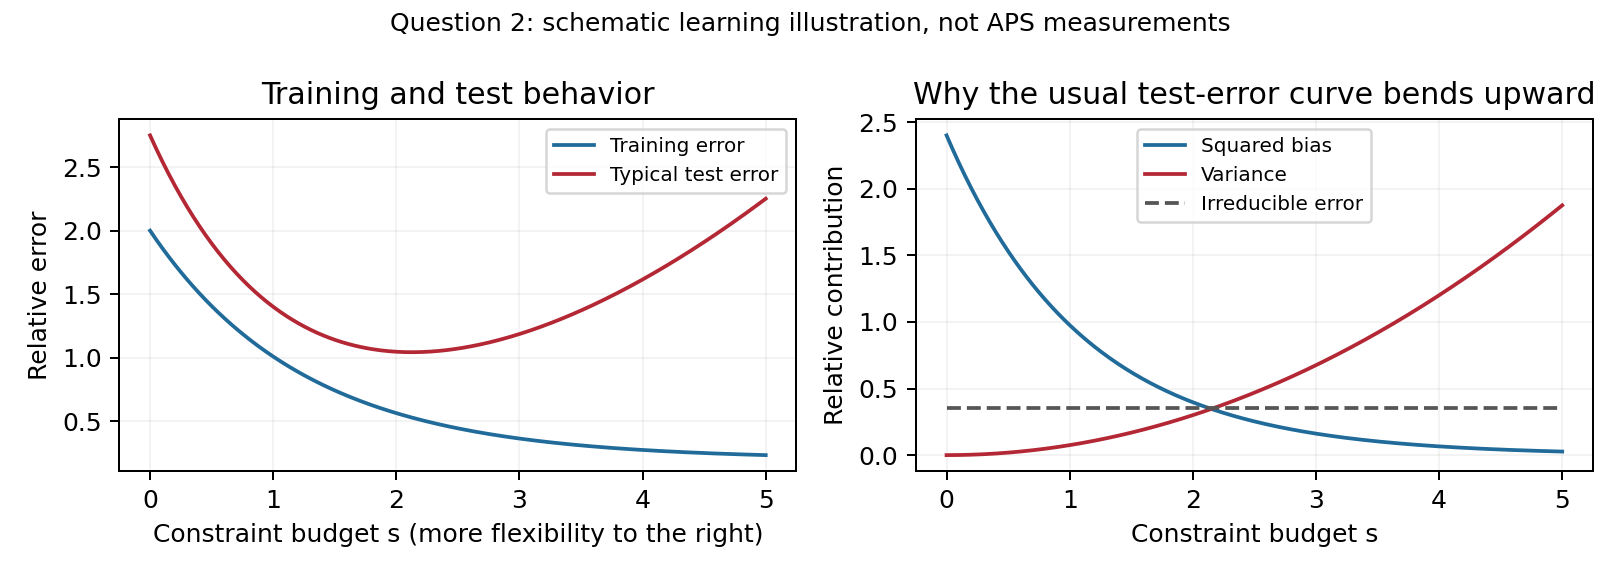

In [14]:
from learning_plots import lasso_trends
lasso_trends()
display(Image(filename=str(OUT/"q2_lasso_trends.png"), width=500))

## 3. ISLR 6.6.5 - identical predictors in ridge and lasso

Both predictor columns contain the same information. Since the predictors and response are centered, the unpenalized intercept is zero. Write x_i for the common predictor value and t=beta_1+beta_2. Also let A=sum_i x_i^2 and B=sum_i x_i y_i. The fitted values depend on t, not on how that total is split between the two coefficients.

### 3(a)

Ridge minimizes sum_i [y_i-x_i(beta_1+beta_2)]^2 + lambda(beta_1^2+beta_2^2). The first term measures the fit, and the second discourages large coefficients. The intercept is not penalized.

### 3(b)

Differentiating gives -2 sum_i x_i[y_i-x_i(beta_1+beta_2)] + 2 lambda beta_j=0 for j=1,2. Subtracting the equations leaves 2 lambda(beta_1-beta_2)=0. For lambda>0, beta_1=beta_2=B/(2A+lambda). Ridge shares the effect equally between identical predictors. At lambda=0, equal coefficients are not required.

### 3(c)

Lasso instead minimizes sum_i [y_i-x_i(beta_1+beta_2)]^2 + lambda(|beta_1|+|beta_2|). For a fixed total t, the smallest possible penalty is lambda|t|. Any same-sign split of t achieves it, so several coefficient pairs can describe the same fit.

### 3(d)

For A>0, the best total is t*=sign(B) max(|B|-lambda/2,0)/A. If t*>0, every pair (u,t*-u) with 0<=u<=t* works equally well. If t*<0, use t*<=u<=0. This shows why lasso coefficients need not be unique even though their predictions are the same. When t*=0, the minimum-penalty pair is (0,0), so nonuniqueness is not guaranteed. In the geometric picture, an RSS contour can touch a whole edge of the L1 diamond.

### Illustration for 3(a)-(d)
The constrained ridge example has one contact point; lasso has an equally good edge. These are illustrative constraints, not a shared penalty value.

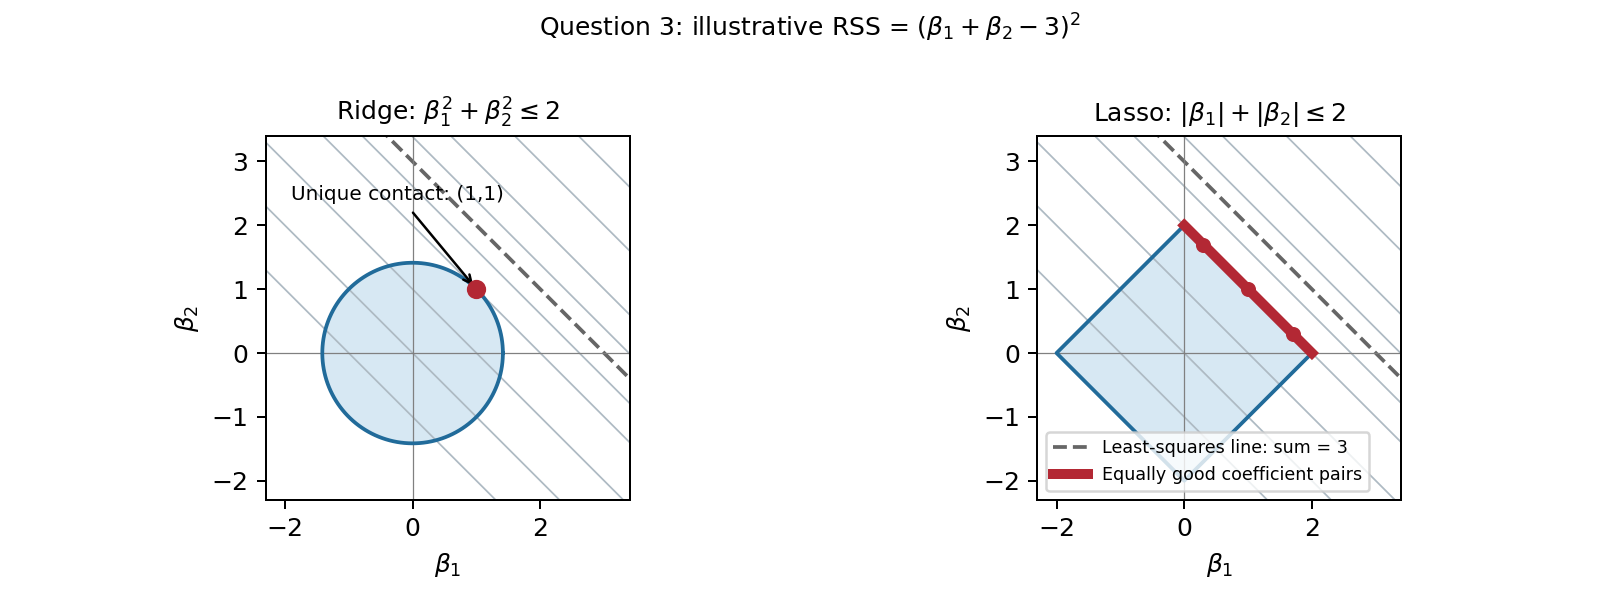

In [15]:
from learning_plots import identical_predictor_geometry
identical_predictor_geometry()
display(Image(filename=str(OUT/"q3_ridge_lasso_geometry.png"), width=500))

## 4. ISLR 8.4.5 - combining ten tree predictions

For majority voting, each tree gets one vote: it votes Red when its Red probability is above 0.5. Six trees vote Red and four vote Green, so the final prediction is Red.

Averaging probabilities gives a different answer. The ten probabilities add to 4.5, so the average Red probability is 0.45. That makes the average Green probability 0.55, and this method predicts Green. The difference is that voting ignores how confident each tree is, while averaging keeps that information.

### Figure for Question 4
These are the exact ten probabilities from the exercise; the dashed line marks 0.5.

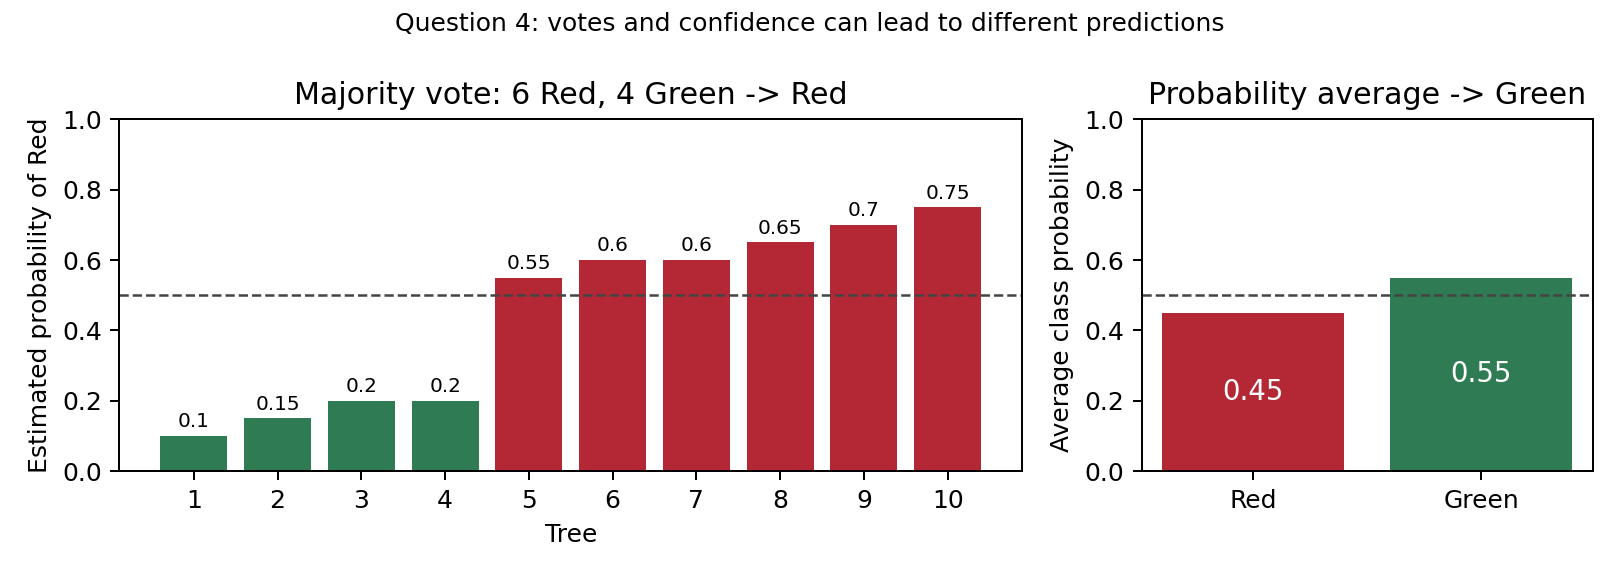

In [16]:
from learning_plots import tree_aggregation
tree_aggregation()
display(Image(filename=str(OUT/"q4_tree_aggregation.png"), width=500))

## 5. ISLR 9.7.3 - understanding the maximal-margin classifier

### 5(a)

The seven points are (3,4), (2,2), (4,4), (1,4), (2,1), (4,3), and (4,1). Points 1-4 are Red and points 5-7 are Blue. The figure labels each point so it is easy to relate the geometry to the calculations.

### 5(b)

The optimal separating line is x_2=x_1-1/2, or 1/2-x_1+x_2=0. The nearest Red points lie on x_2=x_1, and the nearest Blue points lie on x_2=x_1-1. Putting the separator halfway between these parallel lines leaves equal room on both sides.

### 5(c)

Predict Red when 1/2-x_1+x_2>0 and Blue when it is negative. One set of coefficients is beta_0=1/2, beta_1=-1, beta_2=1. Multiplying all three by the same positive number changes the scale, but not the decision boundary.

### 5(d)

The distance from the separator to either supporting line is (1/2)/sqrt(2)=1/(2 sqrt(2)), about 0.3536. This is the margin on each side; the whole strip is 1/sqrt(2), about 0.7071, wide. Divide the coefficients by sqrt(2) for a unit normal. The canonical functional-margin coefficients are (1,-2,2).

### 5(e)

Points 2, 3, 5 and 6 are the support vectors: (2,2), (4,4), (2,1), and (4,3). They sit on the edges of the margin. The closest Red and Blue convex hulls are 1/sqrt(2) apart, so no separator can leave more than half that distance on both sides.

### 5(f)

Point 7, (4,1), lies safely beyond the Blue supporting line. A small movement that keeps it on that side leaves the support vectors in place, so the maximal-margin separator stays the same.

### 5(g)

The line x_2=x_1-1/4 also separates the classes. However, its Red-side margin is only 1/(4 sqrt(2)), so it leaves less room than the optimal line. The dotted line in the figure shows this alternative.

### 5(h)

Add a Blue point at (2,3). It lies inside the Red convex hull because (2,3)=0.5(2,2)+0.25(3,4)+0.25(1,4). A half-space containing all those Red points also contains this weighted average. The two classes can therefore no longer be strictly separated by a line.

### Figure for 5(a)-(h)
The figure connects the boundary, margins, support vectors, alternative separator and added Blue point.

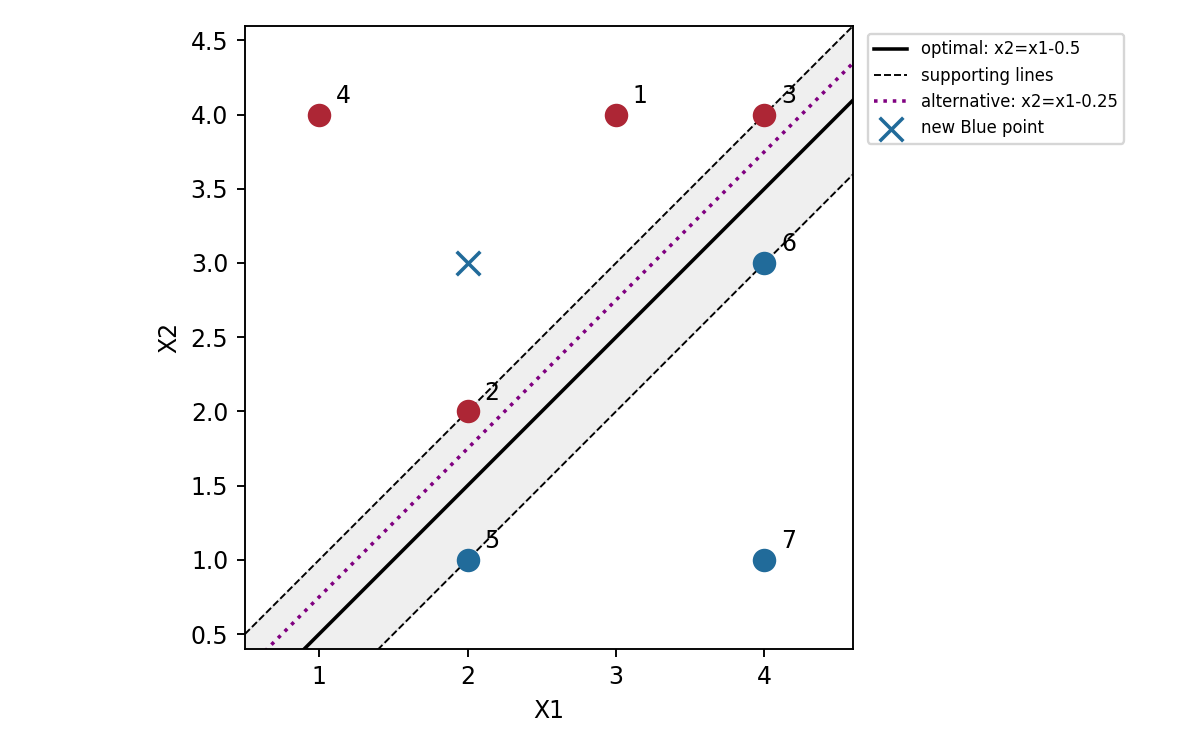

In [17]:
def svm_figure():
    x=np.array([[3,4],[2,2],[4,4],[1,4],[2,1],[4,3],[4,1]])
    fig,ax=plt.subplots(figsize=(7,4.4))
    for i,(a,b) in enumerate(x):
        ax.scatter(a,b,c='#ad2635' if i<4 else '#216b9a',s=80,zorder=4)
        ax.annotate(str(i+1),(a,b),xytext=(7,5),textcoords='offset points')
    z=np.linspace(.5,4.6,100)
    ax.plot(z,z-.5,'k-',label='optimal: x2=x1-0.5')
    ax.plot(z,z,'k--',lw=.8,label='supporting lines'); ax.plot(z,z-1,'k--',lw=.8)
    ax.fill_between(z,z-1,z,color='gray',alpha=.12)
    ax.plot(z,z-.25,':',color='purple',label='alternative: x2=x1-0.25')
    ax.scatter(2,3,marker='x',s=100,c='#216b9a',label='new Blue point')
    ax.set(xlim=(.5,4.6),ylim=(.4,4.6),xlabel='X1',ylabel='X2',aspect='equal')
    ax.legend(fontsize=7,loc='upper left',bbox_to_anchor=(1.01,1)); fig.tight_layout()
    fig.savefig(OUT/'svm_geometry.png',dpi=170); plt.close(fig)

svm_figure()
display(Image(filename=str(OUT/"svm_geometry.png"), width=500))

## 6. Extra practice and references
The optional ISLR 5.4.2, 6.8.4, 8.4.4 and 9.7.2 exercises are excluded. Chapter 6 section numbering differs across editions; answers are identified by exercise number and topic.

Sources: UCI APS data (https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks); scikit-learn imputation and random-forest documentation; XGBoost parameter documentation; imbalanced-learn leakage guidance; Chawla et al. (2002), SMOTE, DOI 10.1613/jair.953; James et al., An Introduction to Statistical Learning. See ENVIRONMENT.md for package versions. The literal XGBoost model-tree issue remains stated in 1(e)-(f).